In [1]:
# Imports
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor, Lambda

In [ ]:
# Download the MNIST dataset

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.5,), (0.5,))
                               ])
mnist_train_dataset = datasets.MNIST(root='/home/savio/Documents/modeling_generation/data', train=True, download=True, transform=transform)
mnist_eval_dataset = datasets.MNIST(root='/home/savio/Documents/modeling_generation/data', train=False, download=True, transform=transform)

# Get a sample image from the training dataset so we can get its shape for our model
sample_img, _ = mnist_train_dataset[0]
print(f"Sample image shape: {sample_img.shape}")  # Should be (1, 28, 28) for MNIST

Sample image shape: torch.Size([1, 28, 28])


In [3]:
# Create data loaders
batch_size = 32
train_loader = DataLoader(mnist_train_dataset, batch_size=batch_size, shuffle=True)
eval_loader = DataLoader(mnist_eval_dataset, batch_size=batch_size, shuffle=False)

In [4]:
# Set the device for training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [5]:
from cnn_classifier import CNNClassifier

# Create an instance of the CNN classifier and move it to the device
classifier = CNNClassifier().to(device)

In [6]:
# Setup the optimizer for training the classifier
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-03)

In [7]:
# Start the training loop for the classifier
num_epochs = 8

loss_history = []

for epoch in range(num_epochs):
    classifier.train()
    total_loss = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = classifier(images)  # [batch_size, num_classes]
        loss = torch.nn.functional.cross_entropy(outputs, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()

        loss_history.append(loss.item())
    
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")

Epoch [1/8], Loss: 0.1254
Epoch [2/8], Loss: 0.0414
Epoch [3/8], Loss: 0.0284
Epoch [4/8], Loss: 0.0209
Epoch [5/8], Loss: 0.0154
Epoch [6/8], Loss: 0.0122
Epoch [7/8], Loss: 0.0104
Epoch [8/8], Loss: 0.0088


In [8]:
# Save the trained classifier model checkpoint
torch.save(classifier.state_dict(), "cnn_classifier_ep_8.ckpt")

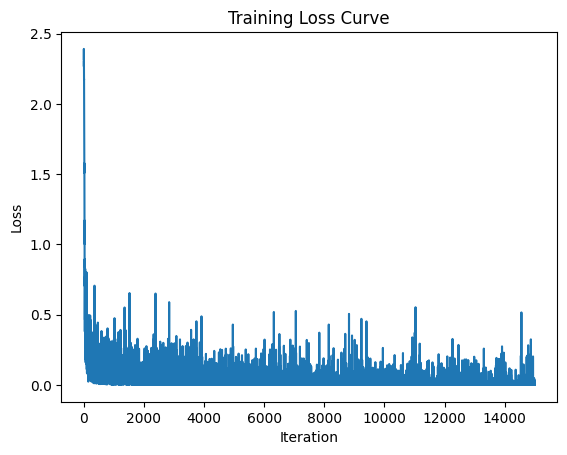

In [9]:
# Plot the training loss curve
import matplotlib.pyplot as plt

plt.plot(loss_history)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.show()

In [10]:
# Evaluate the classifier on the test set
classifier.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in eval_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = classifier(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Test Accuracy: {100 * correct / total:.2f}%")

Test Accuracy: 99.01%


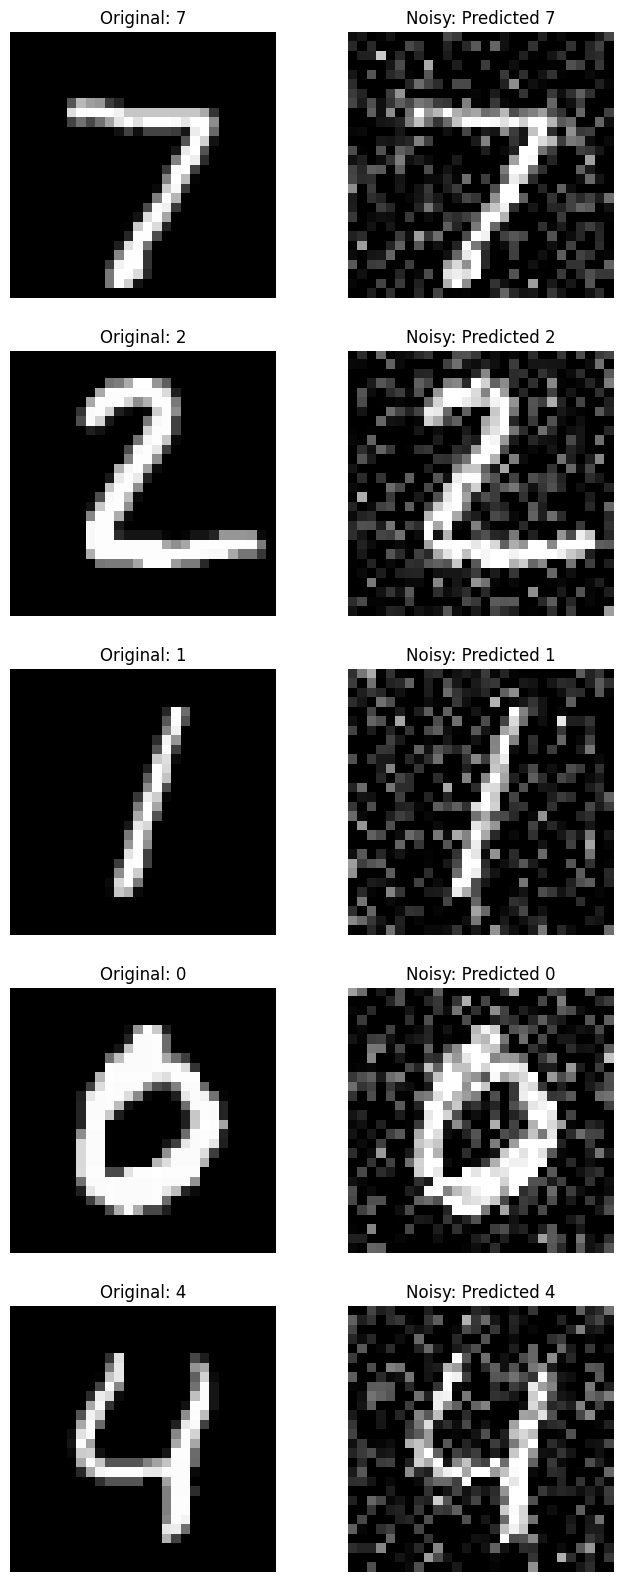

In [11]:
# Sample a few images from the test set , add some noise to them and then run the classifier on these noisy images to see how well it can classify them. 
# Plot the original images, the noisy images, and the predicted labels for the noisy images.

import matplotlib.pyplot as plt

num_test_samples = 5
test_images, test_labels = next(iter(eval_loader))
test_images, test_labels = test_images[:num_test_samples].to(device), test_labels[:num_test_samples].to(device)

# Add noise to the test images
noise = torch.randn_like(test_images) * 0.5  # Adjust the noise level
noisy_test_images = test_images + noise
noisy_test_images = torch.clamp(noisy_test_images, -1, 1)

# Get predictions for the noisy images
classifier.eval()
with torch.no_grad():
    outputs = classifier(noisy_test_images)
    _, predicted_labels = torch.max(outputs.data, dim=1)

# Plot the original images, noisy images, and predicted labels
fig, axes = plt.subplots(num_test_samples, 2, figsize=(8, num_test_samples * 4))
for i in range(num_test_samples):
    # Original image
    axes[i, 0].imshow(test_images[i].cpu().squeeze(), cmap='gray')
    axes[i, 0].set_title(f"Original: {test_labels[i].item()}")
    axes[i, 0].axis('off')
    
    # Noisy image
    axes[i, 1].imshow(noisy_test_images[i].cpu().squeeze(), cmap='gray')
    axes[i, 1].set_title(f"Noisy: Predicted {predicted_labels[i].item()}")
    axes[i, 1].axis('off')